# Homework 4: Evaluation Metrics for Classification

ML Zoomcamp 2026 · Dataset: `course_lead_scoring_2026.csv` · Target: `converted`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [2]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Preparación de datos

Categóricas faltantes → `'NA'`, numéricas faltantes → `0.0`.

In [3]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
categorical = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
numerical = [c for c in df.columns if c not in categorical and c != 'converted']

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
print('Categóricas:', categorical)
print('Numéricas:', numerical)

Categóricas: ['lead_source', 'industry', 'employment_status', 'location']
Numéricas: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


## División de datos (`random_state=1`)

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train['converted'].values
y_val = df_val['converted'].values

df_train = df_train.drop(columns='converted').reset_index(drop=True)
df_val = df_val.drop(columns='converted').reset_index(drop=True)
len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## Pregunta 1: ROC AUC como importancia de variables (train)

Si el AUC < 0.5 se invierte la variable.

In [6]:
aucs = {}
for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    aucs[c] = auc
pd.Series(aucs).sort_values(ascending=False)

lead_score                  0.788225
interaction_count           0.764920
number_of_courses_viewed    0.722989
annual_income               0.608198
dtype: float64

## Pregunta 2: AUC del modelo en validación

In [7]:
features = categorical + numerical

def train(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_tr[features].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model

def predict(df_, dv, model):
    X = dv.transform(df_[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
auc_val = roc_auc_score(y_val, y_pred)
round(auc_val, 3)

0.732

## Pregunta 3: Precision y Recall

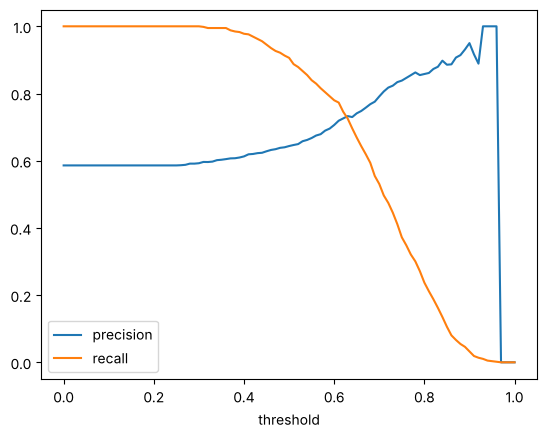

In [8]:
rows = []
for t in np.round(np.arange(0.0, 1.01, 0.01), 2):
    pred = y_pred >= t
    tp = ((pred == 1) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    fn = ((pred == 0) & (y_val == 1)).sum()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    rows.append((t, p, r, f1))
df_scores = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'f1'])

plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold'); plt.legend(); plt.show()

In [9]:
valid = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
valid['diff'] = (valid.precision - valid.recall).abs()
valid.sort_values('diff').head()

,threshold,precision,recall,f1,diff
63,0.63,0.732759,0.725256,0.728988,0.007503
62,0.62,0.725914,0.745734,0.735690,0.019820
64,0.64,0.729875,0.696246,0.712664,0.033629
61,0.61,0.719048,0.773038,0.745066,0.053990
65,0.65,0.741021,0.668942,0.703139,0.072079


## Pregunta 4: F1

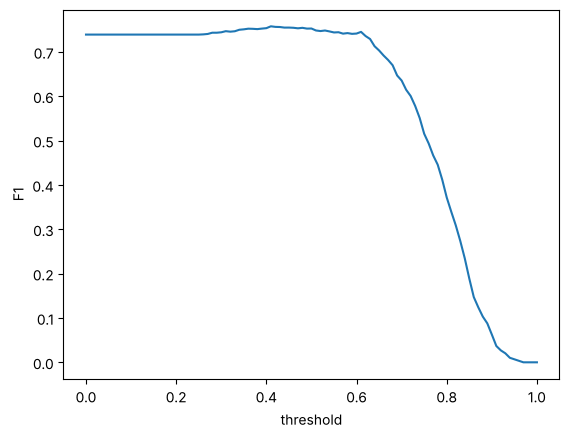

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64

In [10]:
plt.plot(df_scores.threshold, df_scores.f1)
plt.xlabel('threshold'); plt.ylabel('F1'); plt.show()
df_scores.loc[df_scores.f1.idxmax()]

## Pregunta 5: 5-Fold CV

In [11]:
def cv_scores(C=1.0):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for tr_idx, va_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[tr_idx]
        df_va = df_full_train.iloc[va_idx]
        dv, model = train(df_tr, df_tr['converted'].values, C=C)
        scores.append(roc_auc_score(df_va['converted'].values, predict(df_va, dv, model)))
    return np.array(scores)

scores = cv_scores()
print(scores.round(4))
print('mean = %.3f, std = %.3f' % (scores.mean(), scores.std()))

[0.7306 0.7296 0.7363 0.7412 0.7209]
mean = 0.732, std = 0.007


## Pregunta 6: ajuste de C con 5-Fold CV

In [12]:
for C in [0.000001, 0.001, 1]:
    s = cv_scores(C)
    print('C=%s  mean=%.3f  std=%.3f' % (C, s.mean(), s.std()))

C=1e-06  mean=0.617  std=0.019


C=0.001  mean=0.749  std=0.010


C=1  mean=0.732  std=0.007


## Respuestas

| # | Pregunta | Respuesta |
|---|---|---|
| 1 | Mayor AUC | `lead_score` (0.788) |
| 2 | AUC del modelo | 0.732 |
| 3 | Intersección P/R | 0.63 |
| 4 | Umbral F1 máximo | 0.41 (F1 = 0.758) |
| 5 | Std 5-Fold | 0.007 |
| 6 | Mejor C | 0.001 (mean AUC 0.749) |